# Progress 2 v2 — PCD + handcrafted features + ML klasik

Eksperimen awal klasifikasi empat kelas: `normal`, `label_miring`, `label_hilang`, dan `penyok`.

Notebook ini membandingkan ROI tengah tetap dan ROI berjangkar tutup, grayscale dan CLAHE, lalu mengekstrak profil siluet, fitur label, tepi, dan tekstur untuk baseline SVM dan XGBoost.

**Split tetap:** botol 01–02 train, 03 validation, 04 test. Tidak ada random split dan tidak ada augmentasi ulang. Hanya validation yang dipakai memilih konfigurasi. Sel evaluasi test terpisah dan tidak aktif secara default.

Hasil masih preliminary: 20 foto primer dari empat botol; validation/test masing-masing lima foto dari satu botol. Dataset v2 mengganti penyok01 (train) dan penyok03 (validation) dengan foto retake yang cacatnya lebih terlihat; turunannya diperbarui. Retake dilakukan setelah evaluasi awal, sehingga perbandingan v1/v2 bukan bukti peningkatan generalisasi atau kemampuan mendeteksi penyok subtle. Fitur dan grid konfigurasi tetap sama dengan eksperimen awal.


In [1]:
# Jika dependency belum tersedia, install dari requirements.txt di runtime Kaggle.
# Biasanya Kaggle sudah menyediakan OpenCV, scikit-learn, dan XGBoost.
# %pip install -q -r /kaggle/input/progress2-classical/requirements.txt

import json
import os
import sys
from pathlib import Path
from IPython.display import display, Image as DisplayImage

code_candidates = [Path.cwd(), Path.cwd() / "progress2_classical"]
if Path("/kaggle/input").exists():
    code_candidates += sorted({path.parent for path in Path("/kaggle/input").glob("**/experiment.py")})
CODE_DIR = next((path.resolve() for path in code_candidates if (path / "experiment.py").is_file()), None)
if CODE_DIR is None:
    raise FileNotFoundError("Letakkan folder progress2_classical (berisi experiment.py) di samping notebook atau sebagai input Kaggle Dataset.")
sys.path.insert(0, str(CODE_DIR))

from experiment import (
    audit_dataset, dataset_identity, evaluate_test, find_dataset_root, read_csv,
    render_feature_overlays, render_pcd_comparison, run_eda, select_models_and_save,
)

# Jika input Kaggle memuat lebih dari satu versi, tentukan folder v2 secara eksplisit:
# os.environ["AQUVIVA_DATASET_ROOT"] = "/kaggle/input/NAMA-DATASET/dataset_prep"
DATASET_ROOT = find_dataset_root()
DATASET_VERSION = dataset_identity(DATASET_ROOT)["version"]
if DATASET_VERSION != "v2":
    raise ValueError("Notebook ini untuk dataset v2. Arahkan AQUVIVA_DATASET_ROOT ke folder v2.")
output_base = Path("/kaggle/working") if Path("/kaggle/working").exists() else CODE_DIR
OUTPUT_DIR = Path(os.environ.get("AQUVIVA_OUTPUT_DIR", str(output_base / "progress2_results_v2")))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATASET_ROOT)
print("Outputs:", OUTPUT_DIR)


Dataset: /home/fast9/Secondary/CS5/cv/tugas/botol/comvis_dataset_v2/dataset_prep
Outputs: /home/fast9/Secondary/CS5/cv/tugas/botol/progress2_classical/progress2_results_v2


## 1. Audit split, CSV, dan asal augmentasi

Audit ini membaca metadata test hanya untuk memeriksa split dan checksum. Foto test tidak dipakai untuk memilih PCD atau model.

In [2]:
audit = audit_dataset(DATASET_ROOT)
print(json.dumps(audit, indent=2))


{
  "dataset": {
    "version": "v2",
    "revision": {
      "version": "v2",
      "date": "2026-11-17",
      "reason": "Retake penyok01 dan penyok03 karena cacat pada foto awal kurang terlihat. Revisi setelah evaluasi awal, bukan bukti peningkatan generalisasi.",
      "changes": [
        {
          "filename": "penyok03.jpg",
          "old_sha256": "8e475fefa5302bf19c8114631802903984921b0344885de00a8aa382e2f41e4a",
          "new_sha256": "c1cccd7b4cd176eef9a052e1b2a07dacf0ed13caa5776b83668bc44c95efc7a0",
          "drive_file_id": "1a7HxoAHzHaA-8M0ToPP6TNp8_4iJLF6z",
          "drive_modified_time": "2026-11-17T16:12:52.377Z",
          "split": "validation"
        },
        {
          "filename": "penyok01.jpg",
          "old_sha256": "b9fafade7bb8e90b0dc6141ab4ebd0fea3b33fdbe346be4f3f73869c0d62e49d",
          "new_sha256": "5690d42bc900675e06f9aebc6586009ba13a85e25174cc250311a1633c48fc94",
          "drive_file_id": "1i5z3quG-DuKYavVj9tpSP4BBPa5oZL0r",
          "drive_

## 2. EDA: foto primer dan turunan augmentasi

Grafik pertama menghitung 20 foto primer per split. Grafik kedua memisahkan 10 foto train asli dari 290 turunan augmentasi. Grid foto visual hanya menampilkan 10 foto train asli agar pemeriksaan visual tidak membuka holdout test sebelum konfigurasi dikunci.

{
  "dataset": {
    "version": "v2",
    "revision": {
      "version": "v2",
      "date": "2026-11-17",
      "reason": "Retake penyok01 dan penyok03 karena cacat pada foto awal kurang terlihat. Revisi setelah evaluasi awal, bukan bukti peningkatan generalisasi.",
      "changes": [
        {
          "filename": "penyok03.jpg",
          "old_sha256": "8e475fefa5302bf19c8114631802903984921b0344885de00a8aa382e2f41e4a",
          "new_sha256": "c1cccd7b4cd176eef9a052e1b2a07dacf0ed13caa5776b83668bc44c95efc7a0",
          "drive_file_id": "1a7HxoAHzHaA-8M0ToPP6TNp8_4iJLF6z",
          "drive_modified_time": "2026-11-17T16:12:52.377Z",
          "split": "validation"
        },
        {
          "filename": "penyok01.jpg",
          "old_sha256": "b9fafade7bb8e90b0dc6141ab4ebd0fea3b33fdbe346be4f3f73869c0d62e49d",
          "new_sha256": "5690d42bc900675e06f9aebc6586009ba13a85e25174cc250311a1633c48fc94",
          "drive_file_id": "1i5z3quG-DuKYavVj9tpSP4BBPa5oZL0r",
          "drive_

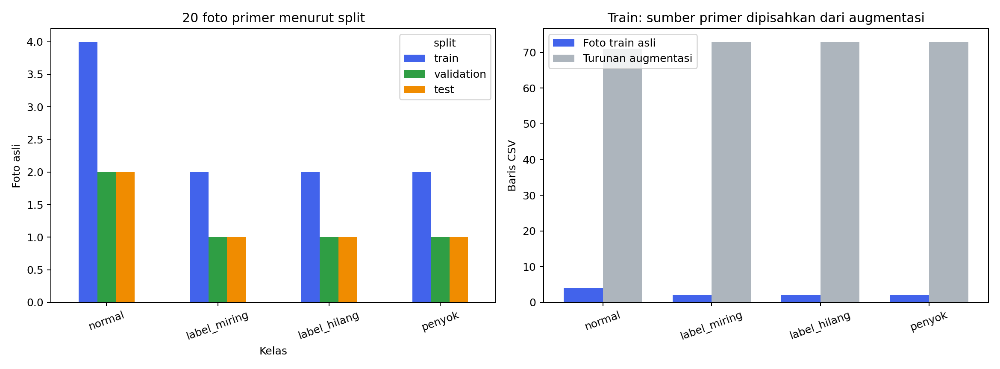

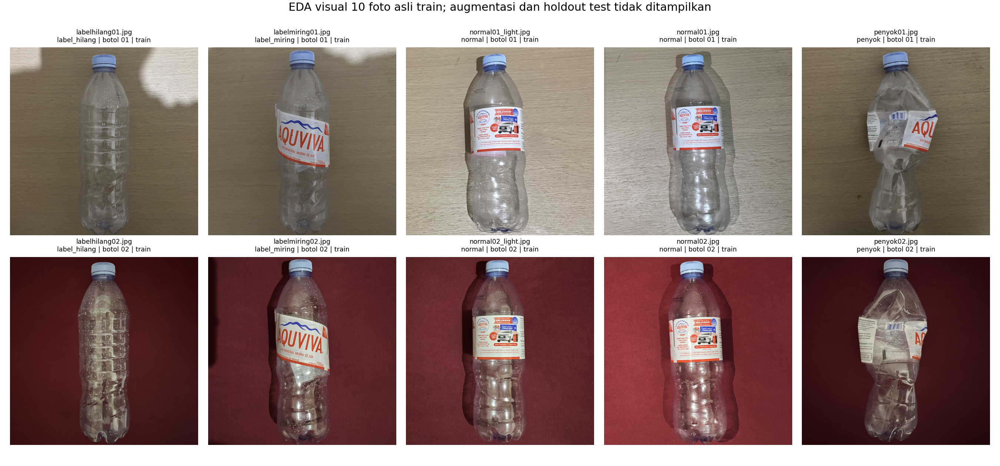

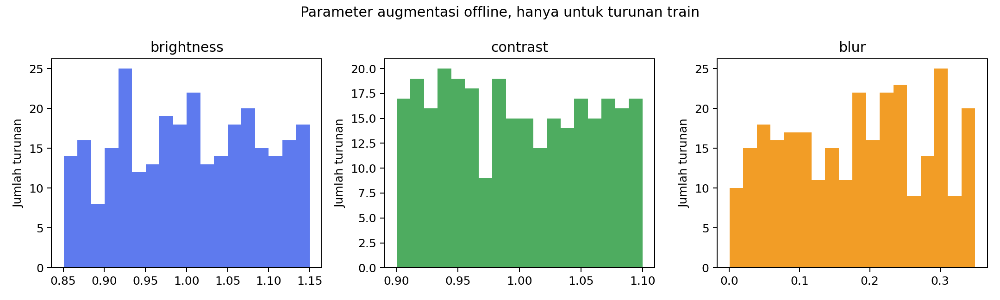

primary_photos
split      label                       
test       label_hilang               1
           label_miring               1
           normal                     2
           penyok                     1
train      label_hilang               2
           label_miring               2
           normal                     4
           penyok                     2
validation label_hilang               1
           label_miring               1
           normal                     2
           penyok                     1

train_rows
label        is_augmented            
label_hilang 0                      2
             1                     73
label_miring 0                      2
             1                     73
normal       0                      4
             1                     71
penyok       0                      2
             1                     73

In [3]:
eda_summary = run_eda(DATASET_ROOT, OUTPUT_DIR, audit_summary=audit)
print(json.dumps(eda_summary, indent=2))
for filename in ["eda_class_counts.png", "eda_original_photos.png", "eda_augmentation_parameters.png"]:
    display(DisplayImage(filename=str(OUTPUT_DIR / filename)))
display(read_csv(DATASET_ROOT, "metadata_original.csv").groupby(["split", "label"]).size().rename("primary_photos").to_frame())
display(read_csv(DATASET_ROOT, "train.csv").groupby(["label", "is_augmented"]).size().rename("train_rows").to_frame())


## 3. Bandingkan PCD dan ROI dengan foto train

Panel membandingkan foto mentah, ROI yang dipusatkan pada tutup dan sumbu badan, Otsu threshold, Canny, Canny + closing 3×3, dan CLAHE. Threshold dan edge maps adalah kandidat visual, bukan mask botol yang sudah tervalidasi.

{
  "visual_path": "/home/fast9/Secondary/CS5/cv/tugas/botol/progress2_classical/progress2_results_v2/pcd_roi_comparison_train_originals.png",
  "cap_detection_rate": 1.0,
  "axis_detection_rate": 0.7,
  "rows": 10
}


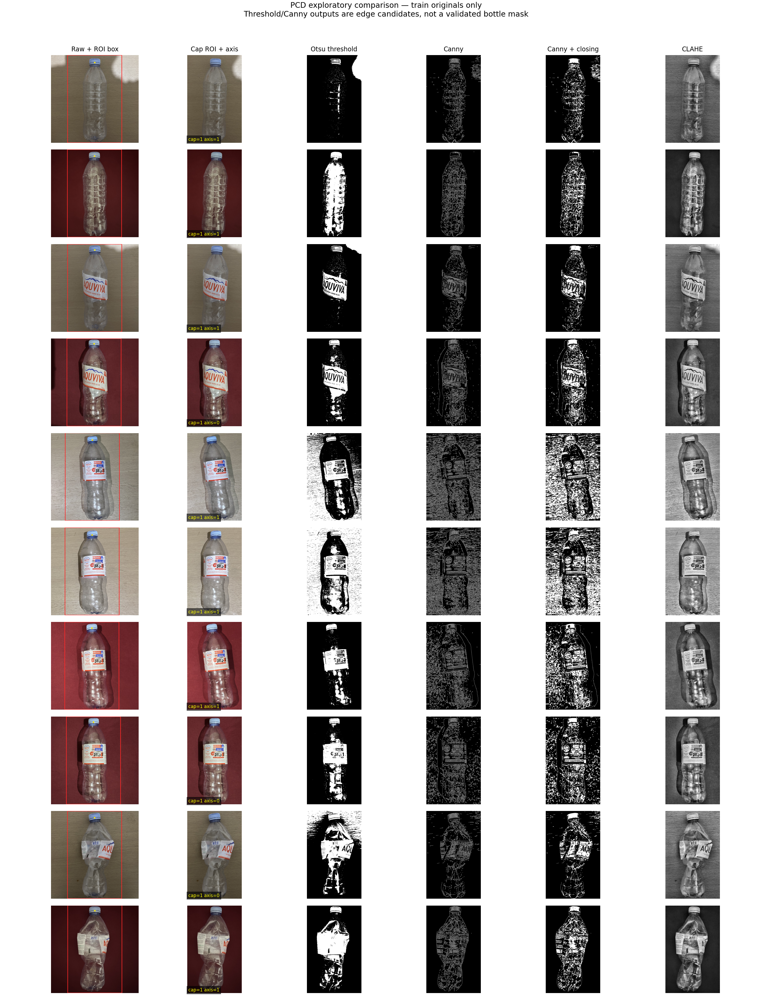

,filename,label,cap_found,axis_found,axis_angle_deg,axis_fit_r2,roi_fallback,cap_center_x,cap_center_y,crop_x0,crop_x1
0,img/labelhilang01.jpg,label_hilang,1,1,1.503382,0.189541,0,383,65,145,621
1,img/labelhilang02.jpg,label_hilang,1,1,3.183463,0.328740,0,381,58,143,619
2,img/labelmiring01.jpg,label_miring,1,1,3.494716,0.491856,0,383,51,145,621
3,img/labelmiring02.jpg,label_miring,1,0,NaN,0.003207,0,377,46,139,615
4,img/normal01.jpg,normal,1,1,-4.635695,0.400463,0,362,62,124,600
5,img/normal01_light.jpg,normal,1,1,1.860280,0.180196,0,360,65,122,598
6,img/normal02.jpg,normal,1,1,-4.020991,0.260361,0,358,53,120,596
7,img/normal02_light.jpg,normal,1,0,NaN,0.012639,0,372,48,134,610
8,img/penyok01.jpg,penyok,1,0,NaN,0.110937,0,382,59,144,620
9,img/penyok02.jpg,penyok,1,1,2.389450,0.197700,0,384,47,146,622


In [4]:
pcd_summary = render_pcd_comparison(DATASET_ROOT, OUTPUT_DIR)
print(json.dumps(pcd_summary, indent=2))
display(DisplayImage(filename=str(OUTPUT_DIR / "pcd_roi_comparison_train_originals.png")))
display(__import__("pandas").read_csv(OUTPUT_DIR / "pcd_roi_diagnostics_train_originals.csv"))


## 4. Ekstraksi fitur dan pemilihan baseline

Fitur yang tidak berhasil diukur disimpan sebagai nilai kosong dan diimputasi hanya dari train. Referensi profil normal dibentuk dari foto train asli kelas normal. Fitur lokal kanan atas berasal dari rancangan untuk foto subtle versi awal dan tetap dipakai bersama profil badan keseluruhan pada retake v2; lokasi cacat baru tidak diasumsikan hanya di kanan atas. SVM memakai imputer + scaler yang di-fit pada train; XGBoost memakai imputer train. Grid kecil dipilih berdasarkan macro-F1 validation.

,model,roi_mode,contrast_mode,settings,macro_f1,accuracy,validation_predictions
0,svm,center_roi,gray,"{""C"": 0.1, ""class_weight"": ""balanced"", ""gamma""...",0.375,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
1,svm,center_roi,gray,"{""C"": 1.0, ""class_weight"": ""balanced"", ""gamma""...",0.375,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
2,svm,center_roi,gray,"{""C"": 10.0, ""class_weight"": ""balanced"", ""gamma...",0.375,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
3,svm,cap_roi,gray,"{""C"": 2.0, ""class_weight"": ""balanced"", ""gamma""...",0.375,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
4,svm,cap_roi,gray,"{""C"": 0.1, ""class_weight"": ""balanced"", ""gamma""...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
5,svm,cap_roi,gray,"{""C"": 1.0, ""class_weight"": ""balanced"", ""gamma""...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
6,xgboost,center_roi,gray,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
7,xgboost,center_roi,gray,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_est...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
8,xgboost,center_roi,gray,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."
9,xgboost,center_roi,gray,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_est...",0.350,0.4,"[""label_hilang"", ""label_miring"", ""label_miring..."


,model,filename,source_filename,bottle_id,view_id,qc_note,true_label,predicted_label,correct,roi_mode,contrast_mode,cap_found,axis_found,label_found,label_angle_deg,profile_valid_fraction,profile_dev_mean_abs,profile_right_upper_inward_mean,profile_right_upper_inward_max
0,svm,img/labelhilang03.jpg,labelhilang03.jpg,03,standard,NaN,label_hilang,label_hilang,True,center_roi,gray,1.0,0.0,0,NaN,0.7,0.089936,0.037640,0.037640
1,svm,img/labelmiring03.jpg,labelmiring03.jpg,03,standard,Perbedaan sisi label antara normal dan label m...,label_miring,label_miring,True,center_roi,gray,1.0,1.0,1,14.512496,0.8,0.095544,0.065476,0.118172
2,svm,img/normal03.jpg,normal03.jpg,03,standard,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,0.0,1,NaN,0.9,0.128949,0.086572,0.179884
3,svm,img/normal03_light.jpg,normal03_light.jpg,03,light,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,1.0,1,NaN,1.0,0.094695,0.090336,0.137430
4,svm,img/penyok03.jpg,penyok03.jpg,03,standard,Foto retake menggantikan foto penyok subtle pa...,penyok,normal,False,center_roi,gray,1.0,1.0,1,-8.483683,0.8,0.089286,0.049501,0.151654
5,xgboost,img/labelhilang03.jpg,labelhilang03.jpg,03,standard,NaN,label_hilang,label_hilang,True,center_roi,gray,1.0,0.0,0,NaN,0.7,0.089936,0.037640,0.037640
6,xgboost,img/labelmiring03.jpg,labelmiring03.jpg,03,standard,Perbedaan sisi label antara normal dan label m...,label_miring,label_miring,True,center_roi,gray,1.0,1.0,1,14.512496,0.8,0.095544,0.065476,0.118172
7,xgboost,img/normal03.jpg,normal03.jpg,03,standard,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,0.0,1,NaN,0.9,0.128949,0.086572,0.179884
8,xgboost,img/normal03_light.jpg,normal03_light.jpg,03,light,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,1.0,1,NaN,1.0,0.094695,0.090336,0.137430
9,xgboost,img/penyok03.jpg,penyok03.jpg,03,standard,Foto retake menggantikan foto penyok subtle pa...,penyok,label_miring,False,center_roi,gray,1.0,1.0,1,-8.483683,0.8,0.089286,0.049501,0.151654


,model,class,precision,recall,f1,support,macro_f1,accuracy
0,svm,normal,0.000000,0.0,0.0,2,0.375,0.4
1,svm,label_miring,0.333333,1.0,0.5,1,0.375,0.4
2,svm,label_hilang,1.000000,1.0,1.0,1,0.375,0.4
3,svm,penyok,0.000000,0.0,0.0,1,0.375,0.4
4,xgboost,normal,0.000000,0.0,0.0,2,0.350,0.4
5,xgboost,label_miring,0.250000,1.0,0.4,1,0.350,0.4
6,xgboost,label_hilang,1.000000,1.0,1.0,1,0.350,0.4
7,xgboost,penyok,0.000000,0.0,0.0,1,0.350,0.4


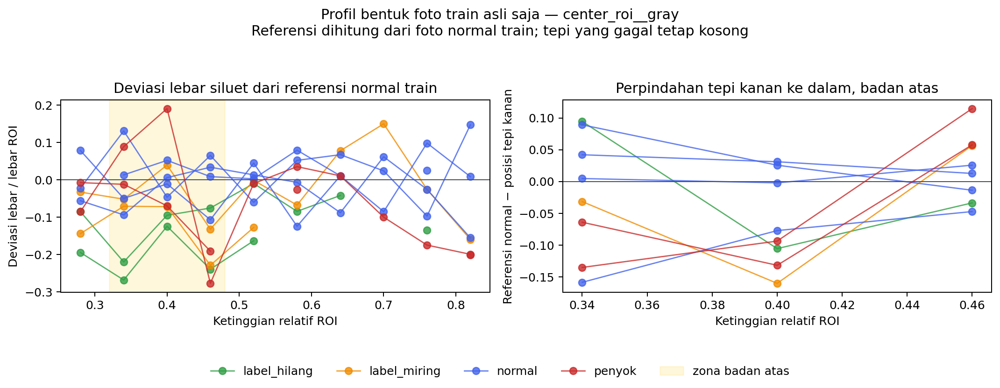

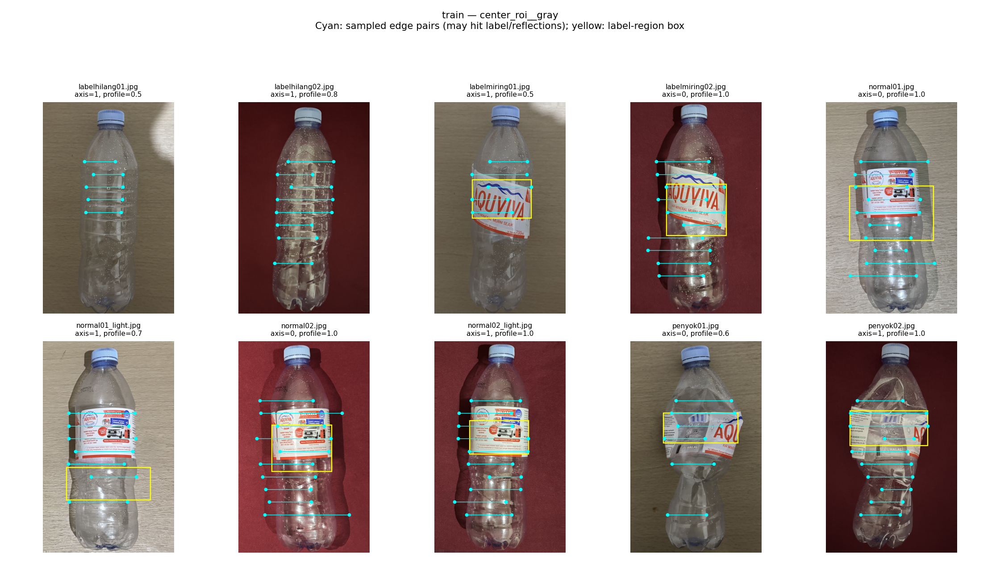

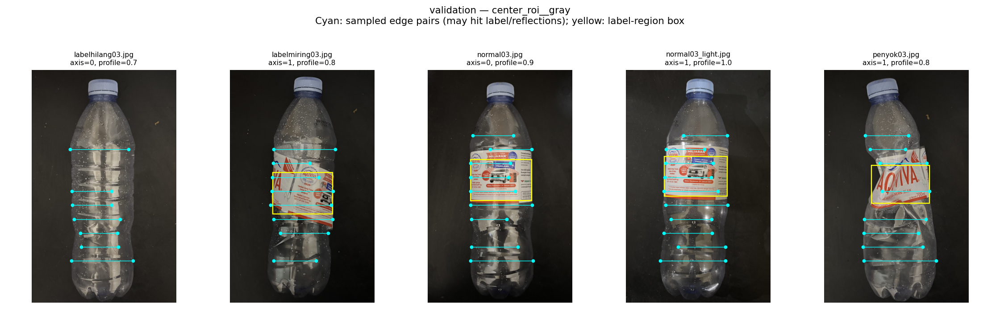

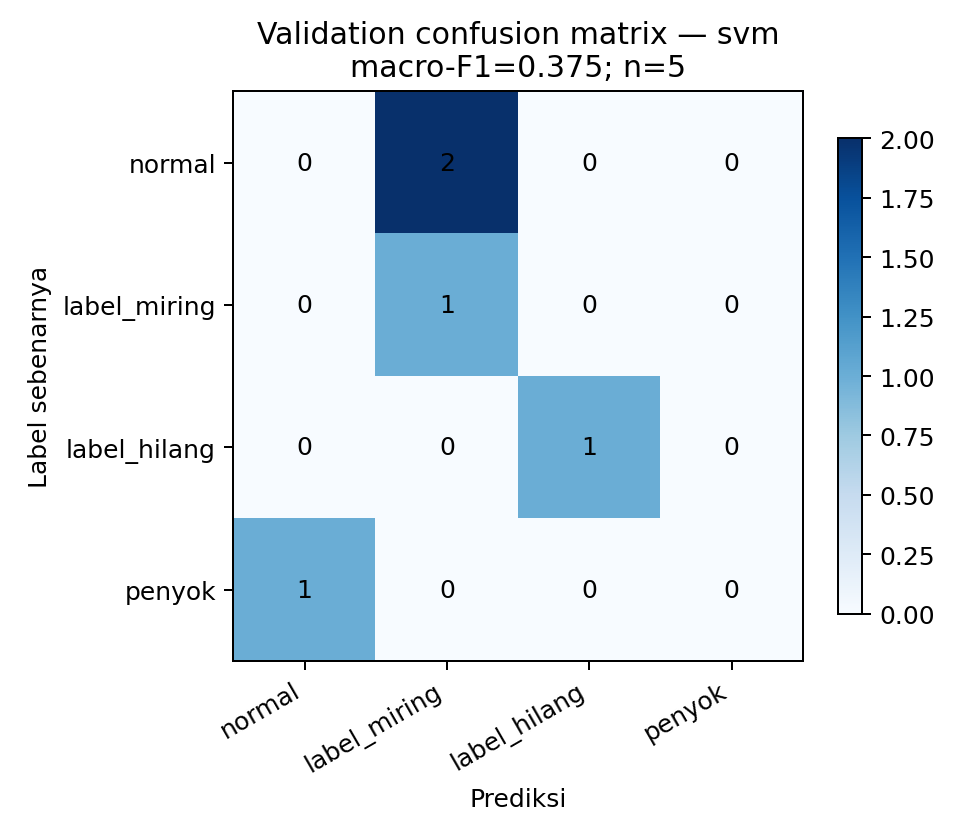

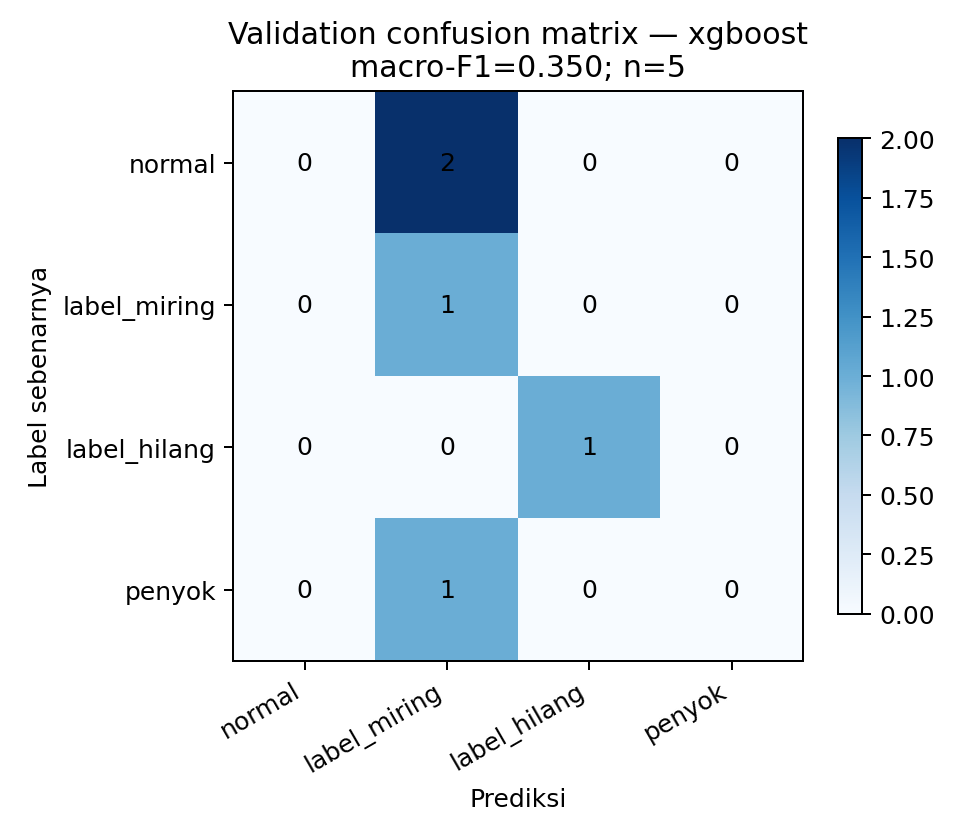

,variant,data_role,sample_count,cap_found_rate,axis_found_rate,label_found_rate,profile_valid_fraction_mean,profile_right_upper_valid_fraction_mean,label_angle_available_count
0,center_roi__gray,train_original,10,1.0,0.6,0.8,0.81,1.000000,1
1,center_roi__gray,validation,5,1.0,0.6,0.8,0.84,0.800000,2
2,center_roi__clahe,train_original,10,1.0,0.6,0.8,0.90,0.966667,1
3,center_roi__clahe,validation,5,1.0,0.6,0.8,0.80,0.733333,2
4,cap_roi__gray,train_original,10,1.0,0.7,0.8,0.80,0.900000,2
5,cap_roi__gray,validation,5,1.0,0.6,0.8,0.80,0.733333,2
6,cap_roi__clahe,train_original,10,1.0,0.7,0.8,0.91,1.000000,2
7,cap_roi__clahe,validation,5,1.0,0.6,0.8,0.80,0.866667,2


# Progress 2 classical ML — validation summary

Dataset version: v2. Features and search grid are unchanged from the initial experiment.

Configuration selection used validation macro-F1. The test split has not been evaluated by this run.

| Model | Pipeline | Parameters | Validation macro-F1 | Accuracy | Correct |
|---|---|---|---:|---:|---:|
| svm | center_roi__gray | `{"C": 0.1, "class_weight": "balanced", "gamma": "scale", "kernel": "linear"}` | 0.375 | 0.400 | 2/5 |
| xgboost | center_roi__gray | `{"learning_rate": 0.05, "max_depth": 2, "n_estimators": 80}` | 0.350 | 0.400 | 2/5 |

Validation contains five original photos from bottle 03. Each class except normal has one validation photo, so one error changes that class recall by 1.0.
The primary dataset has 20 original photos from four physical bottles. The 290 train augmentations are photometric descendants and do not add independent observations.
Version v2 uses retaken penyok01 (train) and penyok03 (validation) with more visibl

In [5]:
model_results = select_models_and_save(DATASET_ROOT, OUTPUT_DIR)
render_feature_overlays(DATASET_ROOT, OUTPUT_DIR)
search = model_results["search"]
display(search.groupby("model", group_keys=False).head(6).reset_index(drop=True))
display(model_results["predictions"])
display(__import__("pandas").read_csv(OUTPUT_DIR / "validation_metrics_by_class.csv"))
selected_variants = sorted({item["selected_variant"] for item in model_results["selected"].values()})
for variant in selected_variants:
    display(DisplayImage(filename=str(OUTPUT_DIR / f"silhouette_profile_deviation_{variant}.png")))
    for role in ("train", "validation"):
        display(DisplayImage(filename=str(OUTPUT_DIR / f"feature_overlay_{role}_{variant}.png")))
for filename in ["validation_confusion_svm.png", "validation_confusion_xgboost.png"]:
    display(DisplayImage(filename=str(OUTPUT_DIR / filename)))
display(__import__("pandas").read_csv(OUTPUT_DIR / "feature_detection_summary.csv"))
print((OUTPUT_DIR / "experiment_summary.md").read_text())


## 5. Konfigurasi terkunci dan kesalahan validation

`selected_config.json` menyimpan varian ROI/contrast, parameter tiap model, referensi normal train, dan metrik validation. Tinjau setiap prediksi validation yang salah bersama status deteksi ROI/label dan catatan akuisisi.

In [6]:
selected = json.loads((OUTPUT_DIR / "selected_config.json").read_text())
print(json.dumps(selected, indent=2))
errors = __import__("pandas").read_csv(OUTPUT_DIR / "validation_error_analysis.csv")
display(errors)


{
  "dataset": {
    "version": "v2",
    "revision": {
      "version": "v2",
      "date": "2026-11-17",
      "reason": "Retake penyok01 dan penyok03 karena cacat pada foto awal kurang terlihat. Revisi setelah evaluasi awal, bukan bukti peningkatan generalisasi.",
      "changes": [
        {
          "filename": "penyok03.jpg",
          "old_sha256": "8e475fefa5302bf19c8114631802903984921b0344885de00a8aa382e2f41e4a",
          "new_sha256": "c1cccd7b4cd176eef9a052e1b2a07dacf0ed13caa5776b83668bc44c95efc7a0",
          "drive_file_id": "1a7HxoAHzHaA-8M0ToPP6TNp8_4iJLF6z",
          "drive_modified_time": "2026-11-17T16:12:52.377Z",
          "split": "validation"
        },
        {
          "filename": "penyok01.jpg",
          "old_sha256": "b9fafade7bb8e90b0dc6141ab4ebd0fea3b33fdbe346be4f3f73869c0d62e49d",
          "new_sha256": "5690d42bc900675e06f9aebc6586009ba13a85e25174cc250311a1633c48fc94",
          "drive_file_id": "1i5z3quG-DuKYavVj9tpSP4BBPa5oZL0r",
          "drive_

,model,filename,source_filename,bottle_id,view_id,qc_note,true_label,predicted_label,correct,roi_mode,contrast_mode,cap_found,axis_found,label_found,label_angle_deg,profile_valid_fraction,profile_dev_mean_abs,profile_right_upper_inward_mean,profile_right_upper_inward_max
0,svm,img/normal03.jpg,normal03.jpg,3,standard,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,0.0,1,NaN,0.9,0.128949,0.086572,0.179884
1,svm,img/normal03_light.jpg,normal03_light.jpg,3,light,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,1.0,1,NaN,1.0,0.094695,0.090336,0.137430
2,svm,img/penyok03.jpg,penyok03.jpg,3,standard,Foto retake menggantikan foto penyok subtle pa...,penyok,normal,False,center_roi,gray,1.0,1.0,1,-8.483683,0.8,0.089286,0.049501,0.151654
3,xgboost,img/normal03.jpg,normal03.jpg,3,standard,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,0.0,1,NaN,0.9,0.128949,0.086572,0.179884
4,xgboost,img/normal03_light.jpg,normal03_light.jpg,3,light,Perbedaan sisi label antara normal dan label m...,normal,label_miring,False,center_roi,gray,1.0,1.0,1,NaN,1.0,0.094695,0.090336,0.137430
5,xgboost,img/penyok03.jpg,penyok03.jpg,3,standard,Foto retake menggantikan foto penyok subtle pa...,penyok,label_miring,False,center_roi,gray,1.0,1.0,1,-8.483683,0.8,0.089286,0.049501,0.151654


## 6. Evaluasi test terpisah — jalankan setelah konfigurasi dikunci

Sel ini sengaja nonaktif. Jangan ubah konfigurasi setelah membaca hasil test. Untuk evaluasi final satu kali, ubah `RUN_FINAL_TEST` menjadi `True` dan jalankan sel ini setelah pemilihan validation selesai.


In [7]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    test_summary = evaluate_test(DATASET_ROOT, OUTPUT_DIR)
    display(test_summary)
else:
    print("Test belum dibaca untuk prediksi. Konfigurasi masih menggunakan hasil validation saja.")


Test belum dibaca untuk prediksi. Konfigurasi masih menggunakan hasil validation saja.


## Catatan interpretasi

- Independensi primer adalah empat botol dan 20 foto. Augmentasi brightness, contrast, dan blur hanya menghasilkan turunan dari 10 foto train.
- Validation dan test masing-masing hanya berisi lima foto dari satu botol; satu kesalahan mengubah recall kelas sebesar satu penuh pada kelas yang hanya punya satu foto.
- Background berubah antar-ID. Normal umumnya memperlihatkan belakang label, sedangkan label miring memperlihatkan depan label. Model dapat memanfaatkan shortcut ini.
- Foto memuat variasi pantulan, tetesan air, orientasi, dan pencahayaan. Skor tinggi tidak membuktikan model memahami cacat.
- Periksa file `pcd_roi_comparison_train_originals.png`, `pcd_roi_diagnostics_train_originals.csv`, dan kolom `label_found` / `profile_valid_fraction` pada tabel fitur sebelum memakai fitur sebagai bukti deteksi fisik.
